# Iris：用 51 个参数复现内部特征与因果干预
150 条样本、4 个尺寸、3 个类别；120 条训练，30 条独立测试。按顺序执行各单元。神经元选择只使用训练集。

## 1. 数据与训练：只用训练集拟合标准化参数
标准化器只拟合训练集；固定数据划分和初始化，不搜索随机种子。

In [1]:
"""A 51-parameter Iris network: inspect, input-ascent, and causal activation patching."""
import hashlib
import json
from pathlib import Path
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT/'experiment.py').exists():
    raise FileNotFoundError('请在 iris 项目目录打开 Notebook')
(ROOT/'results').mkdir(exist_ok=True)
iris=load_iris()
train_ids,test_ids=train_test_split(np.arange(150),test_size=.2,stratify=iris.target,random_state=42)
x_train,y_train=iris.data[train_ids],iris.target[train_ids]
x_test,y_test=iris.data[test_ids],iris.target[test_ids]
scaler=StandardScaler().fit(x_train)
z_train,z_test=scaler.transform(x_train),scaler.transform(x_test)
model=MLPClassifier(hidden_layer_sizes=(6,),activation='tanh',solver='lbfgs',alpha=.1,max_iter=3000,random_state=7)
model.fit(z_train,y_train)
W1,W2=model.coefs_
b1,b2=model.intercepts_
parameter_count=sum(a.size for a in [W1,W2,b1,b2])
accuracy=model.score(z_test,y_test)
print(f'4 -> 6 -> 3; {parameter_count} parameters; train=120, test=30; test correct={round(accuracy*30)}/30')



4 -> 6 -> 3; 51 parameters; train=120, test=30; test correct=29/30


## 2. 手写前向计算，观察全部 6 个隐藏神经元
隐藏层为 tanh，输出为 softmax。用训练集上的类别差异及输出权重选择 h3，再查看留出测试集。

In [2]:
def softmax(logits):
    e=np.exp(logits-np.max(logits,axis=-1,keepdims=True))
    return e/e.sum(axis=-1,keepdims=True)


def forward(z):
    h=np.tanh(z@W1+b1)
    return h,softmax(h@W2+b2)


def fingerprint():
    return hashlib.sha256(b''.join(a.tobytes() for a in [W1,W2,b1,b2])).hexdigest()


before=fingerprint()
h_train,_=forward(z_train)
h_test,p_test=forward(z_test)
np.testing.assert_allclose(p_test,model.predict_proba(z_test),atol=1e-12)
train_means=np.array([h_train[y_train==c].mean(0) for c in range(3)])
test_means=np.array([h_test[y_test==c].mean(0) for c in range(3)])
# Select using TRAINING data only: largest positive contribution to the
# Virginica-versus-Versicolor logit-gap difference between class centroids.
contributions=(train_means[2]-train_means[1])*(W2[:,2]-W2[:,1])
neuron=int(np.argmax(contributions))
sign=float(np.sign(train_means[2,neuron]-train_means[1,neuron]))
print('Training class means, rows=setosa/versicolor/virginica:\n',np.round(train_means,3))
print('Held-out class means:\n',np.round(test_means,3))
print(f'Selected h{neuron+1}; incoming weights:',np.round(W1[:,neuron],3),'bias:',round(b1[neuron],3))
print('Contribution scores:',np.round(contributions,3))



Training class means, rows=setosa/versicolor/virginica:
 [[-0.916  1.     1.    -0.276  0.917 -0.049]
 [ 0.928  0.732  0.714  0.452 -0.928 -0.177]
 [ 0.995 -0.691 -0.718  0.853 -0.995  0.637]]
Held-out class means:
 [[-0.932  1.     1.    -0.091  0.933  0.068]
 [ 0.91   0.768  0.753  0.405 -0.909  0.222]
 [ 0.994 -0.578 -0.608  0.966 -0.994  0.799]]
Selected h3; incoming weights: [ 0.088  0.666 -2.033 -1.239] bias: 2.313
Contribution scores: [-0.08   6.028  6.309 -1.299 -0.08   2.941]


## 3. 特征可视化：冻结网络，沿输入梯度改变四个尺寸
这是数值版特征可视化：权重固定，改变输入使 h3 增大或减小。约束单个尺寸范围，但不保证合成组合对应真实花朵。

In [3]:
low,high=z_train.min(0),z_train.max(0)
representatives=[]
for species in range(3):
    candidates=np.flatnonzero(y_test==species)
    centroid=z_train[y_train==species].mean(0)
    index=candidates[np.argmin(np.sum((z_test[candidates]-centroid)**2,axis=1))]
    representatives.append(int(index))
source=representatives[1]


def ascent(start, direction, steps=40):
    z=start.copy();frames=[]
    for step in range(steps+1):
        h,p=forward(z)
        frames.append({'step':step,'x':scaler.inverse_transform(z[None])[0].tolist(),'h':h.tolist(),'p':p.tolist()})
        gradient=direction*(1-h[neuron]**2)*W1[:,neuron]
        z=np.clip(z+.08*gradient/(np.linalg.norm(gradient)+1e-12),low,high)
    return frames


paths={'increase':ascent(z_test[source],1),'decrease':ascent(z_test[source],-1)}
# Check the analytical input gradient against numerical finite differences.
z=z_test[source].copy();h,_=forward(z)
analytic=(1-h[neuron]**2)*W1[:,neuron]
eps=1e-5
numerical=np.array([(forward(z+np.eye(4)[i]*eps)[0][neuron]-forward(z-np.eye(4)[i]*eps)[0][neuron])/(2*eps) for i in range(4)])
gradient_error=float(np.max(np.abs(analytic-numerical)))
assert gradient_error<1e-7
for label,direction in [('increase',1),('decrease',-1)]:
    assert np.min(direction*np.diff([r['h'][neuron] for r in paths[label]]))>=-1e-12
    print(label,'start:',np.round(paths[label][0]['x'],3),'end:',np.round(paths[label][-1]['x'],3),
          'h:',round(paths[label][-1]['h'][neuron],4))



increase start: [6.1 2.9 4.7 1.4] end: [6.195 3.285 1.1   0.183] h: 1.0
decrease start: [6.1 2.9 4.7 1.4] end: [6.005 2.515 6.9   2.5  ] h: -0.9995


## 4. 因果干预：保持输入与权重不变，只替换一个隐藏激活
输入完全不变；将 h3 换成 Virginica 训练样本的中位激活。可以精确算出它对三个 logits 的影响。

In [4]:
donors=np.median(h_train[y_train==2],axis=0)
patched=h_test.copy()
patched[:,neuron]=donors[neuron]
p_patched=softmax(patched@W2+b2)
ablated=h_test.copy()
ablated[:,neuron]=h_train[:,neuron].mean()
p_ablated=softmax(ablated@W2+b2)
# In this one-hidden-layer network, the causal logit change has an exact formula.
delta_logits=(patched-h_test)@W2
expected=(patched[:,neuron]-h_test[:,neuron])[:,None]*W2[neuron][None,:]
np.testing.assert_allclose(delta_logits,expected,atol=1e-12)
assert fingerprint()==before
print('Representative Versicolor input:',x_test[source])
print('Original probabilities:',np.round(p_test[source],5))
print('Patch selected activation to Virginica training median:',round(donors[neuron],4))
print('Patched probabilities:',np.round(p_patched[source],5))
print('Test accuracy after mean-ablation:',float(np.mean(p_ablated.argmax(1)==y_test)))



Representative Versicolor input: [6.1 2.9 4.7 1.4]
Original probabilities: [0.00176 0.99103 0.00721]
Patch selected activation to Virginica training median: -0.7735
Patched probabilities: [0.00302 0.22744 0.76955]
Test accuracy after mean-ablation: 0.9333333333333333


## 5. 保存全部参数、样本、测量结果与可复用图
保存权重、数据划分、轨迹和图片。消融仅为一次局部干预，不用于宣称模型已改善。

Saved results; all mathematical checks passed.


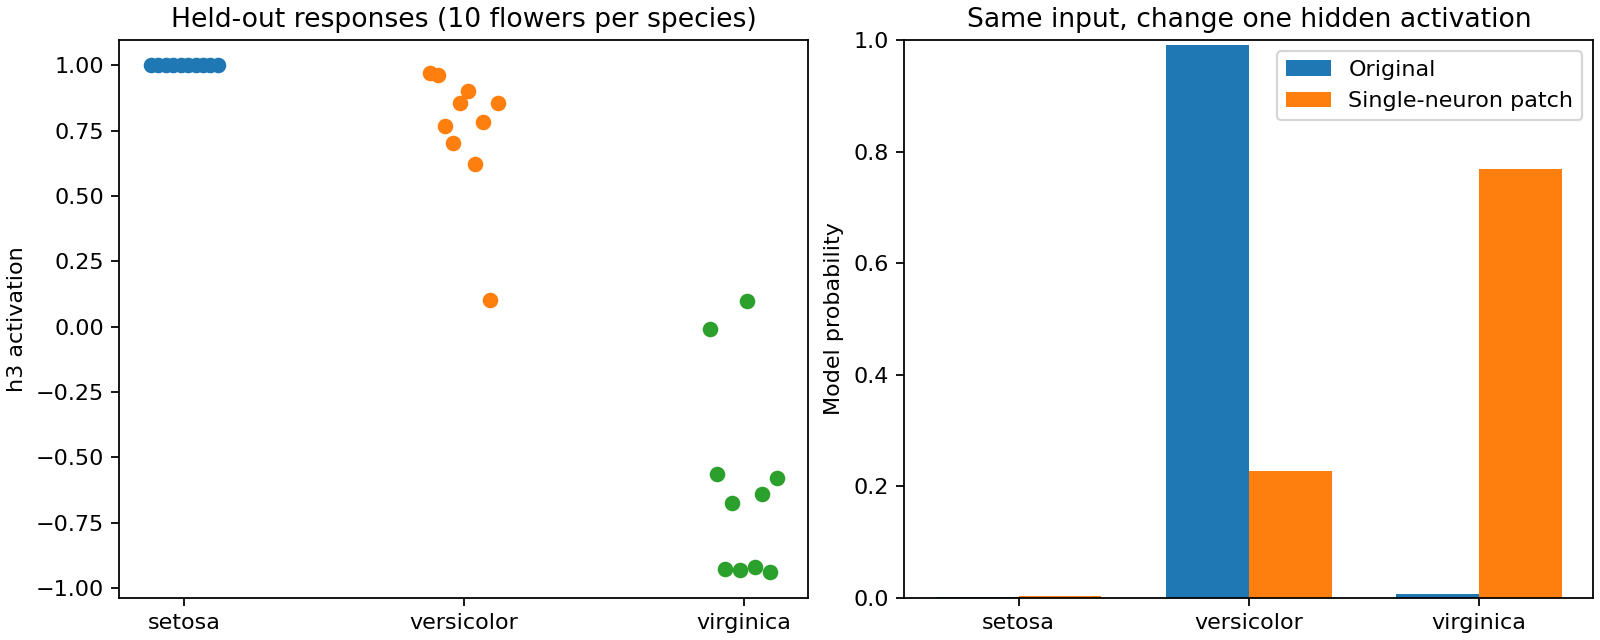

In [5]:
payload={'parameter_count':parameter_count,'accuracy':float(accuracy),'neuron':neuron,'sign':sign,
         'W1':W1.tolist(),'W2':W2.tolist(),'b1':b1.tolist(),'b2':b2.tolist(),
         'mean':scaler.mean_.tolist(),'scale':scaler.scale_.tolist(),
         'low':x_train.min(0).tolist(),'high':x_train.max(0).tolist(),
         'train_ids':train_ids.tolist(),'test_ids':test_ids.tolist(),
         'train_means':train_means.tolist(),'test_means':test_means.tolist(),
         'contributions':contributions.tolist(),'donors':donors.tolist(),
         'feature_names':iris.feature_names,'class_names':iris.target_names.tolist(),
         'representatives':[{'x':x_test[i].tolist(),'id':int(test_ids[i]),'h':h_test[i].tolist(),'p':p_test[i].tolist(),
                             'patched_p':p_patched[i].tolist()} for i in representatives],
         'paths':paths,'gradient_error':gradient_error,'weights_unchanged':fingerprint()==before,
         'test_original_p':p_test.tolist(),'test_patched_p':p_patched.tolist(),
         'ablation_accuracy':float(np.mean(p_ablated.argmax(1)==y_test))}
(ROOT/'results/model.json').write_text(json.dumps(payload,indent=2))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for c,label in enumerate(iris.target_names):
    values=h_test[y_test==c,neuron]
    axes[0].scatter(np.full(len(values),c)+np.linspace(-.12,.12,len(values)),values,label=label)
axes[0].set(xticks=range(3),xticklabels=iris.target_names,ylabel=f'h{neuron+1} activation',title='Held-out responses (10 flowers per species)')
for k,(label,p) in enumerate([('Original',p_test[source]),('Single-neuron patch',p_patched[source])]):
    axes[1].bar(np.arange(3)+k*.36,p,width=.36,label=label)
axes[1].set(xticks=np.arange(3)+.18,xticklabels=iris.target_names,ylabel='Model probability',ylim=(0,1),title='Same input, change one hidden activation')
axes[1].legend()
fig.savefig(ROOT/'results/iris-experiment.png',dpi=160);plt.close(fig)
print('Saved results; all mathematical checks passed.')


## 将四个尺寸画成花形示意
![数值输入优化后的花形对比](results/flower-input-ascent.png)
左：增强 h3；中：原始样本；右：减弱 h3。绿色是花萼，紫色是花瓣，椭圆长短轴对应计算得到的厘米尺寸。颜色与排列固定，仅为示意，不是网络生成的照片。
[查看优化过程动画](results/flower-input-ascent.gif)；运行 `python draw_flowers.py` 可重建。